<a href="https://colab.research.google.com/github/gilberto7martinezr-spec/AF4_Decision_Tree/blob/main/Assignment5_Convolutional.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Assignment 5: Convolutional Neural Network**
Leonardo Saavedra de León - 2093442

Rocío Gabriela Escalera Mireles - 2097046

Gilberto Rubén Cabral Martínez - 2110633

Artificial Intelligence Class

Thuesday - N4

# **Assignment 5: Convolutional Neural Network**
Leonardo Saavedra de León - 2093442

Rocío Gabriela Escalera Mireles - 2097046

Gilberto Rubén Cabral Martínez - 2110633

Artificial Intelligence Class

Thuesday - N4

## 1. Load libraries

This section imports the libraries needed for the project: `numpy` for numerical operations, `matplotlib` to display images, the `mnist` dataset from Keras, and `keras` with its `layers` module to build and train the convolutional neural network.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist

## 2. Load data

The MNIST dataset is loaded with the `load_data()` function from Keras. It contains low-resolution (28x28 pixels) grayscale images of handwritten digits from 0 to 9. The function returns the default split: 60,000 images for training and 10,000 images for testing.

In [ ]:
(train_data, train_labels), (test_data, test_labels) = mnist.load_data()

print("Training data:", train_data.shape, train_labels.shape)
print("Test data:", test_data.shape, test_labels.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data: (60000, 28, 28) (60000,)
Test data: (10000, 28, 28) (10000,)


## 3. Data preprocessing

The pixel values (integers from 0 to 255) are normalized to the range [0, 1] by dividing them by 255, which helps the network train faster and more stably. A channel dimension is also added to each image, so the input shape becomes (28, 28, 1), which is the format expected by the convolutional layers. The labels are kept as integers from 0 to 9.

In [ ]:
train_data = train_data.astype("float32") / 255.0
test_data = test_data.astype("float32") / 255.0

train_data = np.expand_dims(train_data, -1)
test_data = np.expand_dims(test_data, -1)

print(train_data.shape, test_data.shape)

(60000, 28, 28, 1) (10000, 28, 28, 1)


## 4. Model selection and training

A convolutional neural network is built with Keras. It has two convolutional layers (32 and 64 filters of size 3x3, ReLU activation), each followed by a max pooling layer that reduces the size of the feature maps. The result is flattened and passed through a dropout layer (to reduce overfitting) and a final dense layer with 10 neurons and softmax activation, which outputs the probability of each digit.

The model is compiled with the Adam optimizer and the sparse categorical cross-entropy loss function (suitable for multi-class classification with integer labels). The metric used to evaluate the training process is accuracy. Finally, the model is trained with the `fit` function.

In [ ]:
model = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        16,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    train_data, train_labels,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 46s 105ms/step - accuracy: 0.8881 - loss: 0.3697 - val_accuracy: 0.9783 - val_loss: 0.0856
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 100ms/step - accuracy: 0.9659 - loss: 0.1117 - val_accuracy: 0.9833 - val_loss: 0.0571
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 101ms/step - accuracy: 0.9740 - loss: 0.0842 - val_accuracy: 0.9877 - val_loss: 0.0496
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 83s 103ms/step - accuracy: 0.9783 - loss: 0.0714 - val_accuracy: 0.9892 - val_loss: 0.0405
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 81s 101ms/step - accuracy: 0.9806 - loss: 0.0622 - val_accuracy: 0.9877 - val_loss: 0.0386


### Training history

The accuracy obtained in each epoch during training and validation is plotted to observe how the model learned.

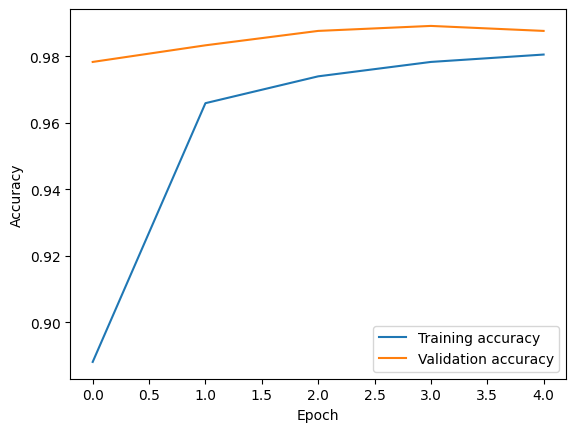

In [ ]:
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

## 5. Model testing

The `evaluate` function is used to measure the performance of the trained model with the test dataset (`test_data`), which the model has not seen during training. Then, 5 different predictions are made with images from the test set. For each one, the predicted digit (the class with the highest probability) is displayed together with the actual value.

In [ ]:
test_loss, test_acc = model.evaluate(test_data, test_labels)
print("Test accuracy:", test_acc)
print("Test loss:", test_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9871 - loss: 0.0371
Test accuracy: 0.9871000051498413
Test loss: 0.037097759544849396


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step
Image 6252: prediction = 6, actual value = 6
Image 4684: prediction = 2, actual value = 2
Image 1731: prediction = 3, actual value = 3
Image 4742: prediction = 7, actual value = 7
Image 4521: prediction = 2, actual value = 2


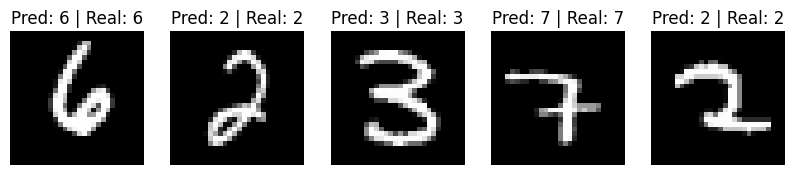

In [ ]:
np.random.seed(42)
indices = np.random.choice(len(test_data), 5, replace=False)

probabilities = model.predict(test_data[indices])
predictions = np.argmax(probabilities, axis=1)

for i, idx in enumerate(indices):
    print(f"Image {idx}: prediction = {predictions[i]}, actual value = {test_labels[idx]}")

plt.figure(figsize=(10, 3))
for i, idx in enumerate(indices):
    plt.subplot(1, 5, i + 1)
    plt.imshow(test_data[idx].squeeze(), cmap="gray")
    plt.title(f"Pred: {predictions[i]} | Real: {test_labels[idx]}")
    plt.axis("off")
plt.show()